# Nhiệm vụ 2: Phân tích Tương quan & So sánh Chuyên sâu Cấu hình - Giá bán (Task 2.1 & 2.2)

**Thành viên thực hiện**: TV3 (Exploratory Data Analysis - EDA)  
**Mã học phần**: IT4930 - Khoa học Dữ liệu & Trí tuệ Kinh doanh  
**Tập dữ liệu**: `data/processed/products_processed.jsonl` ($N = 10.316$ listings)  
**Tài liệu quy chuẩn**: [docs/tv3/tv3.md](file:///d:/NMKHDL/it4930-ecommerce-data-intelligence/docs/tv3/tv3.md) & [docs/feature_contracts_tv3_tv8.md](file:///d:/NMKHDL/it4930-ecommerce-data-intelligence/docs/feature_contracts_tv3_tv8.md)

---
### Mục tiêu nghiên cứu:
1. **Tương quan Bivariate (Pearson & Spearman - Task 2.1)**: Đo lường độ mạnh và hướng liên kết giữa các biến số cấu hình (`ram`, `storage`, `screen_size`, `battery`, `charger`) với biến Giá (`price_vnd` và $\log_{10}(\text{price})$).
2. **Phân tầng Phần cứng (Hardware Stratification - Task 2.1)**: Phân tích biến thiên giá theo từng cấp bậc phần cứng (RAM tiers, Storage tiers, CPU families, GPU classes) và Thương hiệu.
3. **Kiểm định Thống kê Nghiêm ngặt (Task 2.1)**: Thực hiện One-Way ANOVA F-test (tham số) và Kruskal-Wallis H-test (phi tham số) để khẳng định sự khác biệt giá giữa các nhóm cấu hình có ý nghĩa thống kê ($p < 0.05$).
4. **So sánh Đối đầu Chuyên sâu (Laptop vs. Smartphone - Task 2.2)**: Định lượng và đối chiếu sự phân hóa cấu trúc định giá: Laptop (Tài nguyên xử lý: CPU, GPU, RAM, Tản nhiệt/Sạc) vs. Smartphone (Trải nghiệm & Thương hiệu: Brand, ROM, Màn hình OLED). Giải thích các nghịch lý phần cứng (Pin mAh, Camera MP).
5. **Tuyên bố Khoa học Bắt buộc**: Các tương quan và phân tầng là **bằng chứng khám phá thực nghiệm (exploratory associations)**, không cấu thành suy diễn nhân quả (causal inference).

In [1]:
import os
import sys
from pathlib import Path

# Tự động định vị REPO_ROOT (chứa data/processed) và đưa working directory về root
curr = Path.cwd().resolve()
while curr != curr.parent:
    if (curr / "data" / "processed" / "products_processed.jsonl").exists():
        os.chdir(curr)
        break
    curr = curr.parent

if "src/eda/scripts" not in sys.path:
    sys.path.insert(0, "src/eda/scripts")

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Thiết lập đường dẫn import module EDA nội bộ

from eda_stats import (
    load_processed_products,
    compute_bivariate_correlations,
    classify_laptop_hardware,
    classify_smartphone_hardware,
    compute_group_price_stats,
    perform_hypothesis_tests,
    compute_head_to_head_comparison,
    build_pricing_structure_matrix
)
from eda_viz import (
    set_plotting_theme,
    plot_hardware_correlation_heatmaps,
    plot_hardware_price_relationships_laptop,
    plot_hardware_price_relationships_smartphone,
    plot_pricing_drivers_comparison
)

set_plotting_theme()
print("[*] Hệ thống thư viện EDA Task 2 (2.1 & 2.2) đã sẵn sàng!")


[*] Hệ thống thư viện EDA Task 2 (2.1 & 2.2) đã sẵn sàng!


## 1. Tải và Phân loại Cấu hình Phần cứng
Phân tầng chi tiết các nhóm RAM, Storage, CPU Tier và GPU Type cho Laptop, cũng như Storage, RAM, Top Brand và Công nghệ Màn hình cho Smartphone.

In [2]:
df = load_processed_products("data/processed/products_processed.jsonl")
laptop_df = classify_laptop_hardware(df)
phone_df = classify_smartphone_hardware(df)

print(f"Tổng số Laptop: {len(laptop_df):,} | Tổng số Smartphone: {len(phone_df):,}")


Tổng số Laptop: 4,874 | Tổng số Smartphone: 5,442


## 2. Ma trận Tương quan Bivariate (Pearson & Spearman)
Đo lường mức độ tương quan giữa các thông số cấu hình số với biến mục tiêu $\log_{10}(\text{price})$.
- **Laptop**: Trọng số giá dẫn dắt bởi RAM ($\rho = +0.80$), Pin Wh ($\rho = +0.66$), Sạc W ($\rho = +0.72$) và Ổ cứng ($\rho = +0.52$).
- **Smartphone**: Trọng số giá dẫn dắt bởi Bộ nhớ ROM ($\rho = +0.70$) và RAM ($\rho = +0.64$). Ngược lại, Dung lượng Pin mAh hầu như không tương quan ($\rho = +0.04$).

In [3]:
laptop_num_cols = ["installed_ram_gb", "storage_gb", "battery_wh", "screen_size_inch", "charger_watt"]
phone_num_cols = ["installed_ram_gb", "storage_gb", "battery_mah", "screen_size_inch", "charger_watt", "camera_mp"]

corr_laptop = compute_bivariate_correlations(df, "laptop", laptop_num_cols)
corr_phone = compute_bivariate_correlations(df, "smartphone", phone_num_cols)

display(corr_laptop)
display(corr_phone)


,Thuộc tính,Số mẫu hợp lệ (N),Tỷ lệ có dữ liệu (%),Pearson r (log_price),p-value (Pearson log),Spearman rho (log_price),p-value (Spearman log),Spearman rho (raw_price),Mức độ tương quan
0,installed_ram_gb,2379,56.3,0.7289,0.00e+00,0.7962,0.00e+00,0.7962,Rất mạnh (>= 0.7)
1,charger_watt,102,2.4,0.5976,3.35e-11,0.7152,3.07e-17,0.7152,Rất mạnh (>= 0.7)
2,battery_wh,1717,40.7,0.6604,1.18e-215,0.6637,1.69e-218,0.6637,Mạnh (0.5 - 0.7)
3,storage_gb,2804,66.4,0.5247,3.66e-198,0.5225,2.94e-196,0.5225,Mạnh (0.5 - 0.7)
4,screen_size_inch,966,22.9,0.0803,0.0125,0.0927,0.0039,0.0927,Rất yếu (< 0.1)


,Thuộc tính,Số mẫu hợp lệ (N),Tỷ lệ có dữ liệu (%),Pearson r (log_price),p-value (Pearson log),Spearman rho (log_price),p-value (Spearman log),Spearman rho (raw_price),Mức độ tương quan
0,storage_gb,3549,82.0,0.5644,9.08e-298,0.7045,0.00e+00,0.7045,Rất mạnh (>= 0.7)
1,installed_ram_gb,3438,79.5,0.6471,0.00e+00,0.6434,0.00e+00,0.6434,Mạnh (0.5 - 0.7)
2,charger_watt,777,18.0,0.4608,4.26e-42,0.4769,2.25e-45,0.4769,Trung bình (0.3 - 0.5)
3,screen_size_inch,582,13.5,0.5453,2.17e-46,0.1158,0.0051,0.1158,Yếu (0.1 - 0.3)
4,battery_mah,3320,76.7,0.2929,1.17e-66,0.0358,0.0389,0.0358,Rất yếu (< 0.1)
5,camera_mp,614,14.2,0.1805,6.77e-06,0.0277,0.4931,0.0277,Rất yếu (< 0.1)


## 3. Biểu đồ Heatmap Ma trận Tương quan Phi tuyến (Spearman Rank)
So sánh trực quan hai ma trận tương quan giữa Laptop và Smartphone.

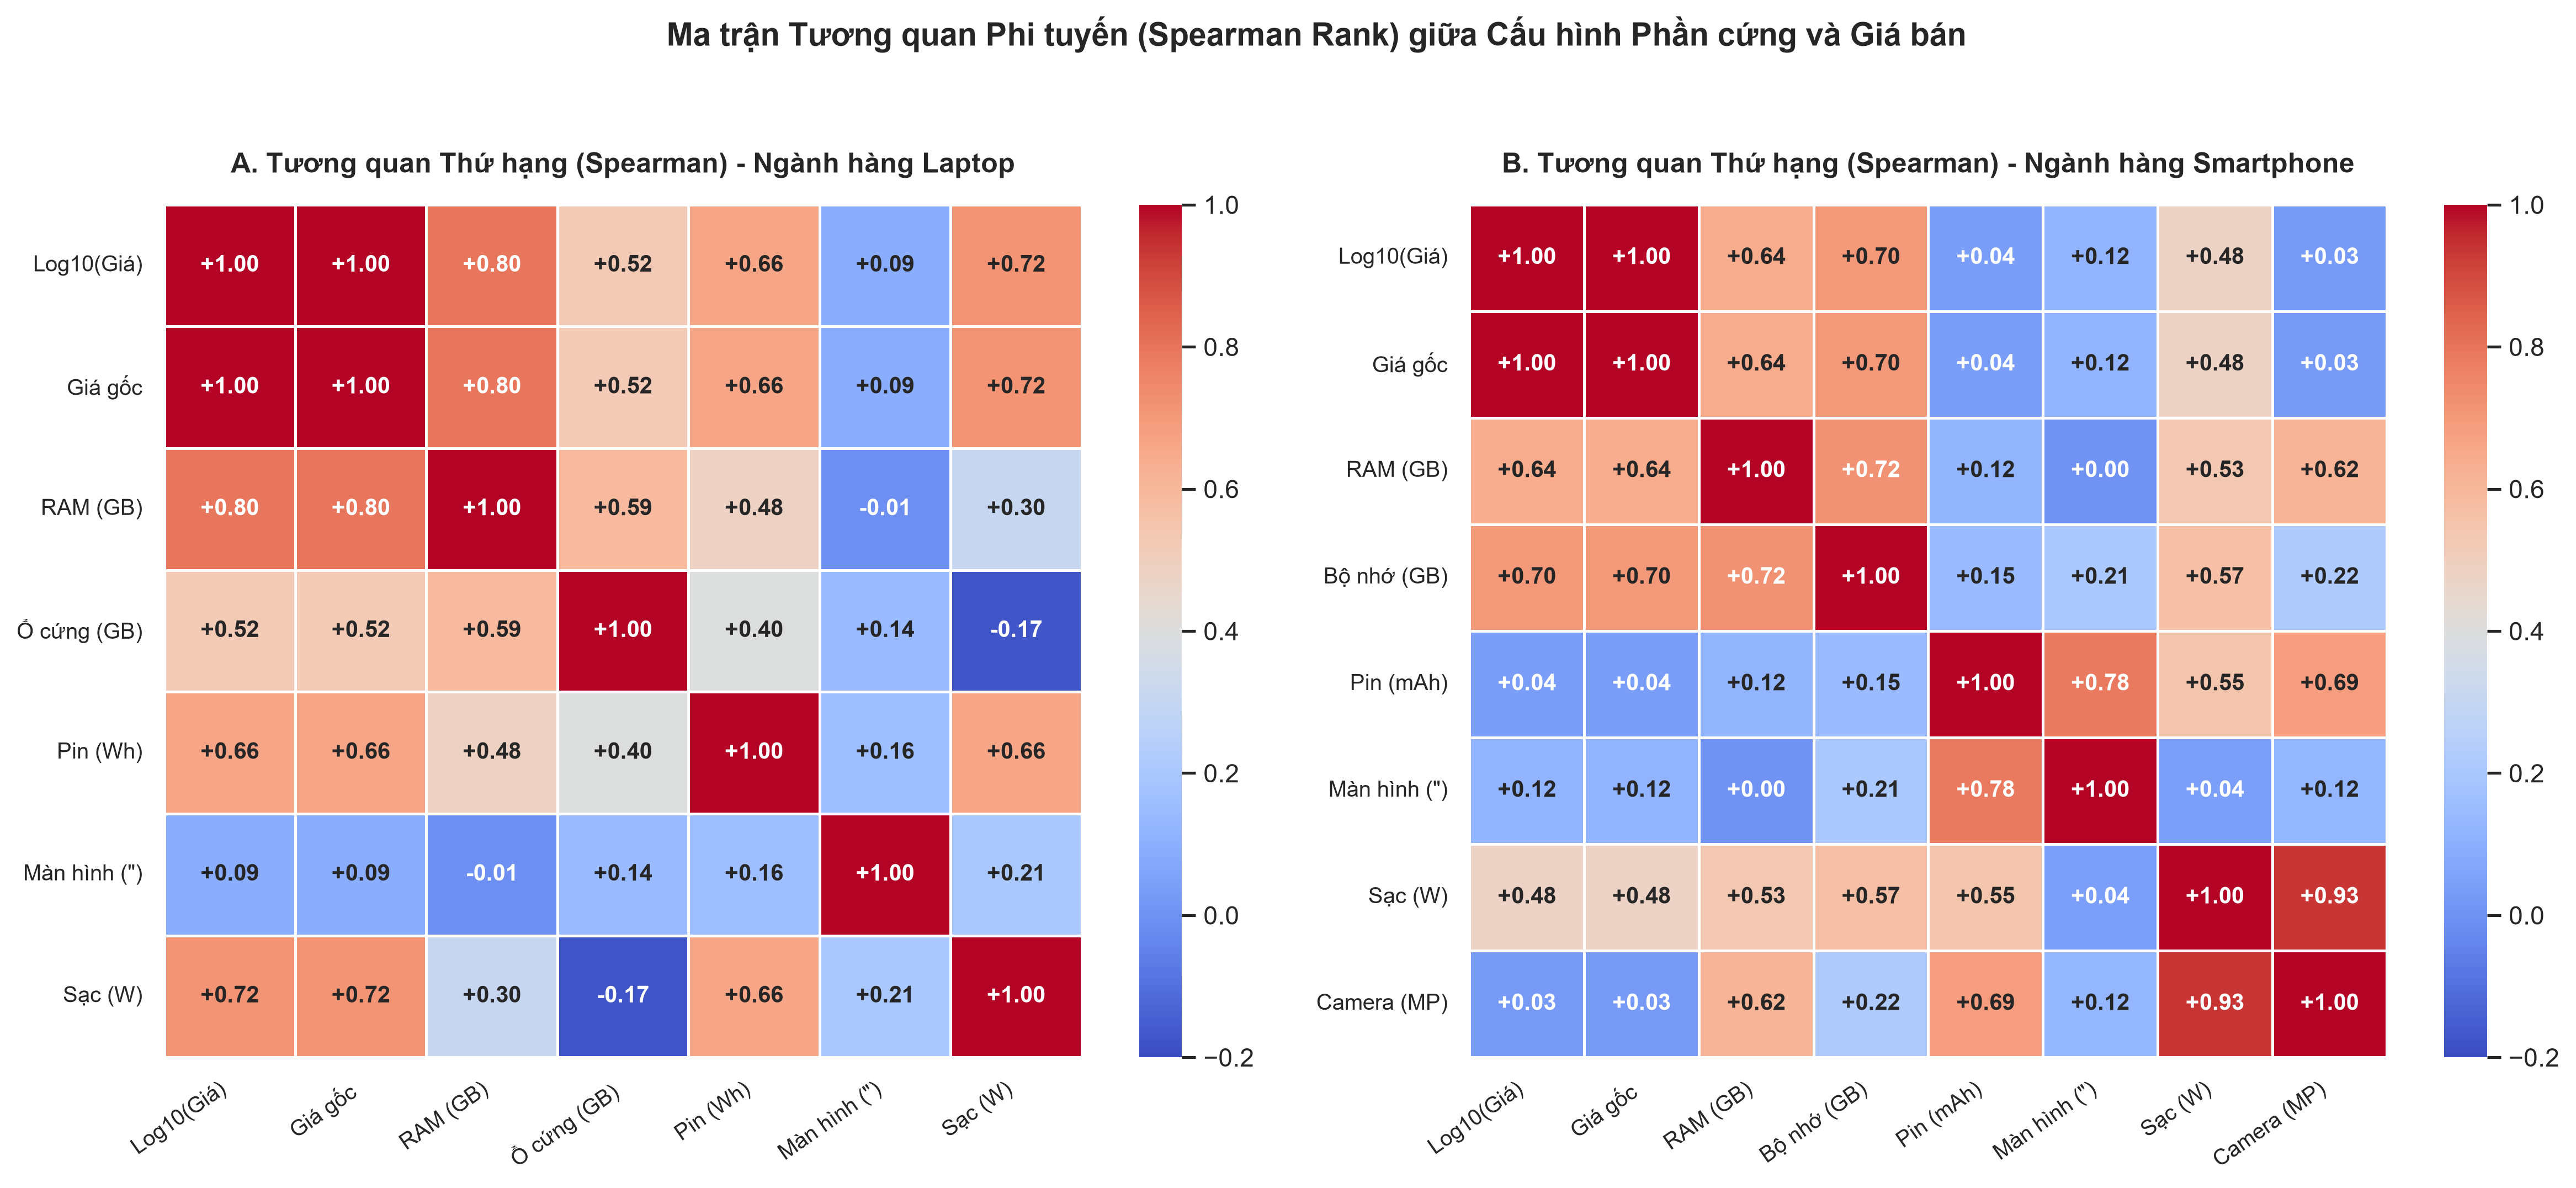

In [4]:
plot_hardware_correlation_heatmaps(df, "src/eda/outputs/figures/fig_2_1_hardware_correlation_heatmaps.png")
from IPython.display import Image
Image("src/eda/outputs/figures/fig_2_1_hardware_correlation_heatmaps.png")


## 4. Phân tích Biến thiên Giá theo Phân tầng Cấu hình Laptop
Khảo sát bước nhảy giá theo RAM, Storage, CPU Tier và GPU Type.

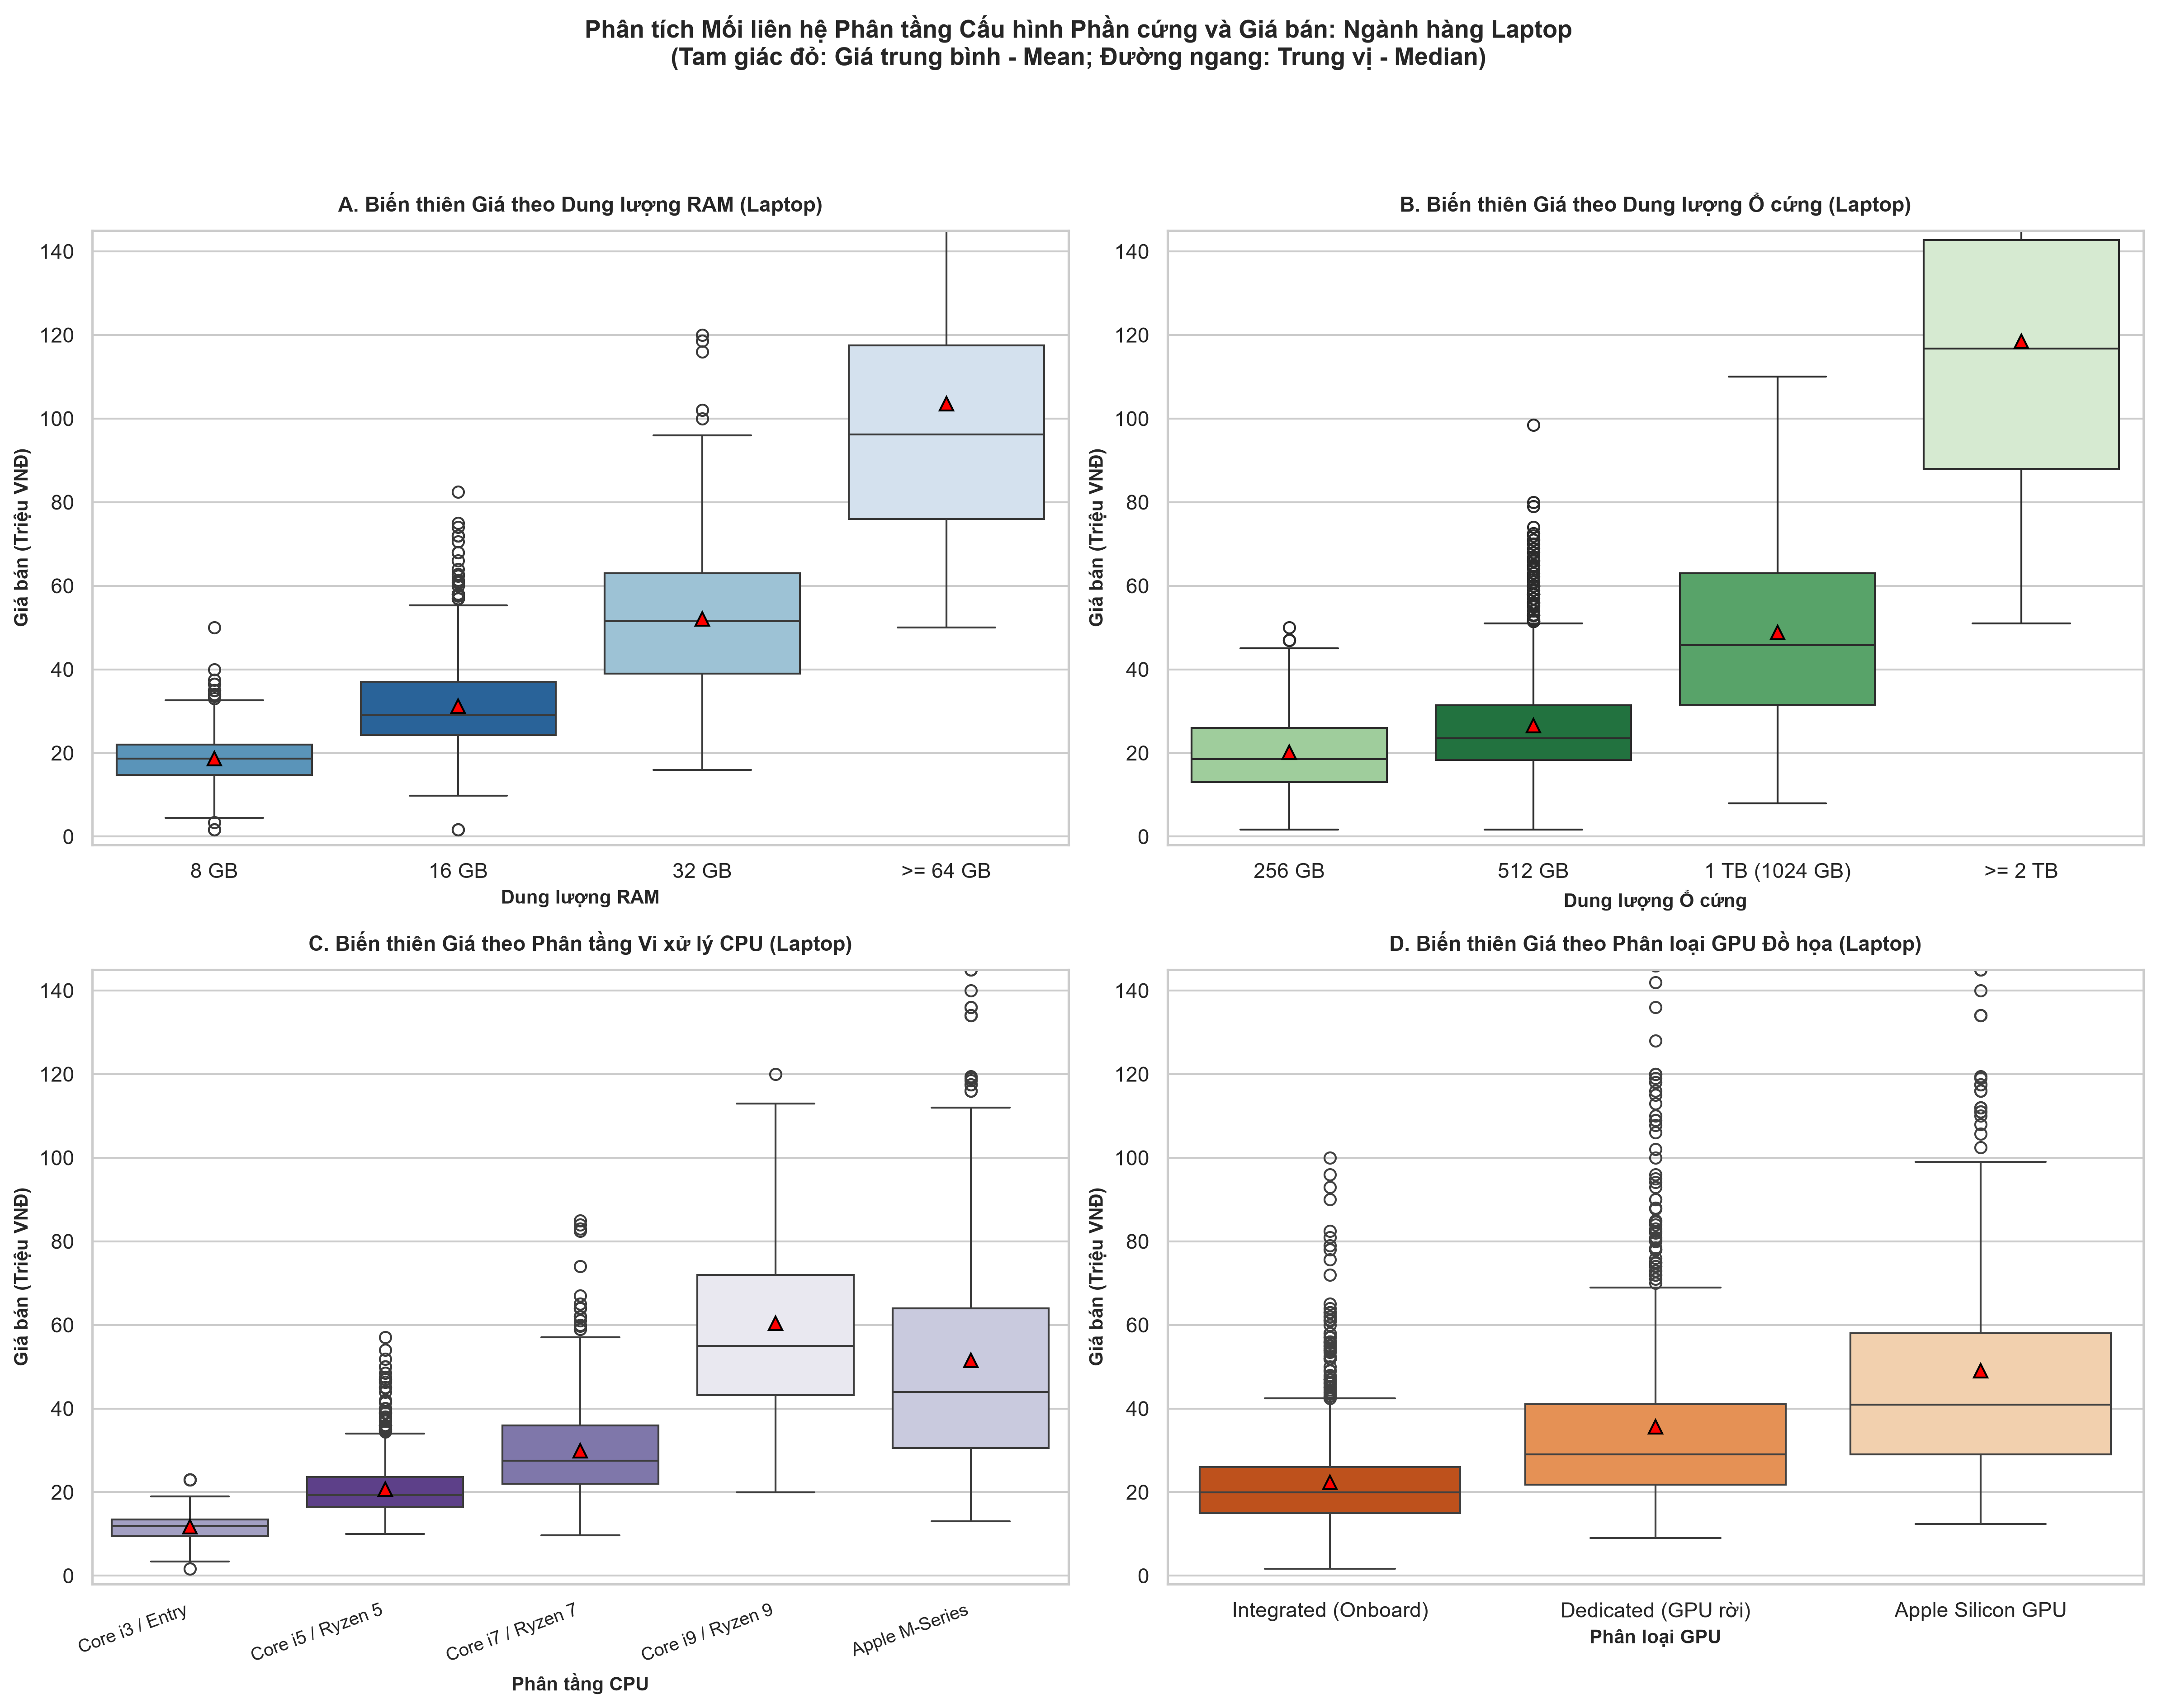

In [5]:
plot_hardware_price_relationships_laptop(laptop_df, "src/eda/outputs/figures/fig_2_1_hardware_price_relationships_laptop.png")
Image("src/eda/outputs/figures/fig_2_1_hardware_price_relationships_laptop.png")


## 5. Phân tích Biến thiên Giá theo Phân tầng Cấu hình & Thương hiệu Smartphone
Khảo sát bước nhảy giá theo ROM, RAM, Top 8 Thương hiệu và Công nghệ Màn hình.

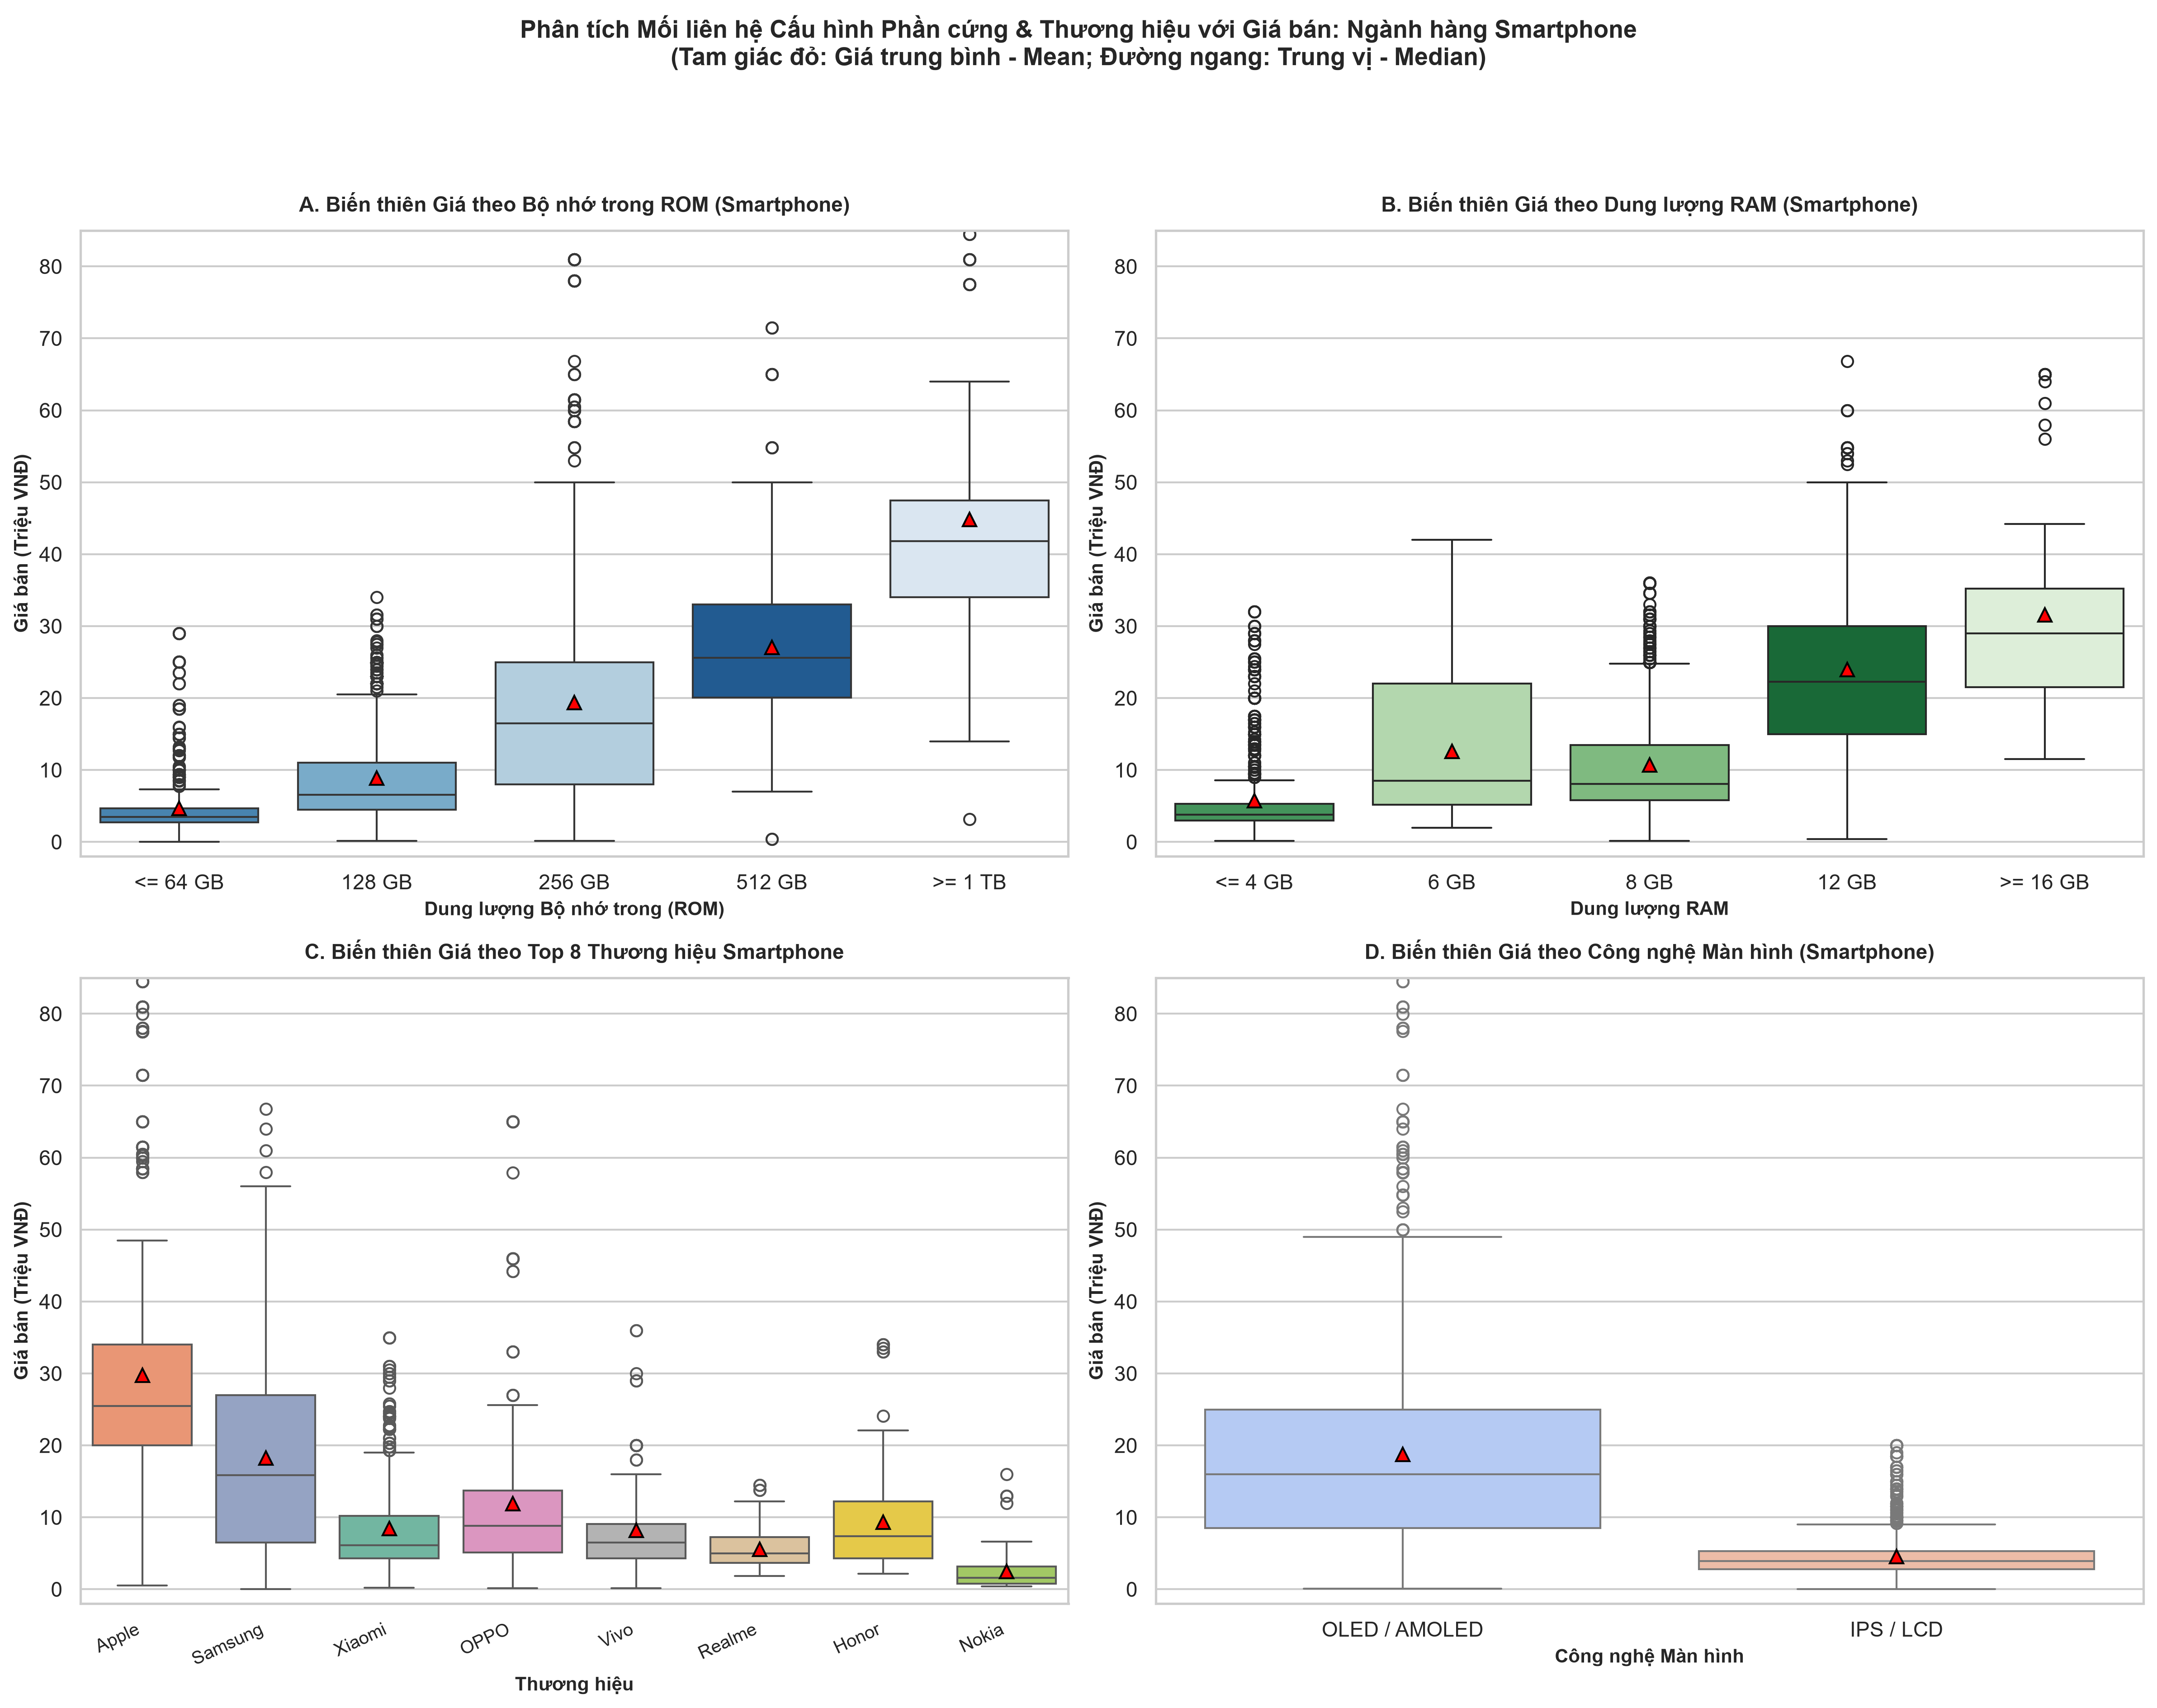

In [6]:
plot_hardware_price_relationships_smartphone(phone_df, "src/eda/outputs/figures/fig_2_1_hardware_price_relationships_smartphone.png")
Image("src/eda/outputs/figures/fig_2_1_hardware_price_relationships_smartphone.png")


## 6. Kiểm định Giả thuyết Thống kê (ANOVA & Kruskal-Wallis)
Kiểm định xem sự khác biệt giá giữa các phân nhóm cấu hình/thương hiệu có thực sự mang ý nghĩa thống kê hay không ($p < 0.05$).

In [7]:
df_classified = pd.concat([laptop_df, phone_df], axis=0, ignore_index=True)
test_factors = [
    ("laptop", "Phân tầng CPU (cpu_tier)", "cpu_tier"),
    ("laptop", "Phân loại GPU (gpu_type)", "gpu_type"),
    ("laptop", "Dung lượng RAM (ram_group)", "ram_group"),
    ("laptop", "Dung lượng Ổ cứng (storage_group)", "storage_group"),
    ("laptop", "Thương hiệu Laptop (brand_norm)", "brand_norm"),
    ("smartphone", "Bộ nhớ trong ROM (storage_group)", "storage_group"),
    ("smartphone", "Dung lượng RAM (ram_group)", "ram_group"),
    ("smartphone", "Thương hiệu Smartphone (brand_norm)", "brand_norm"),
    ("smartphone", "Công nghệ Màn hình (display_group)", "display_group"),
]

tests_summary = perform_hypothesis_tests(df_classified, test_factors)
display(tests_summary)


,Ngành hàng,Yếu tố phân loại,Cột phân tích,Số nhóm so sánh (k),Tổng số mẫu (N),ANOVA F-statistic,ANOVA p-value,Kruskal-Wallis H,Kruskal p-value,Khác biệt có ý nghĩa thống kê?
0,Laptop,Phân tầng CPU (cpu_tier),cpu_tier,6,3232,757.19,0.00e+00,1748.75,0.00e+00,Có (p < 0.001)
1,Laptop,Phân loại GPU (gpu_type),gpu_type,4,3487,399.81,3.65e-223,927.45,9.83e-201,Có (p < 0.001)
2,Laptop,Dung lượng RAM (ram_group),ram_group,4,2379,1346.01,0.00e+00,1485.58,0.00e+00,Có (p < 0.001)
3,Laptop,Dung lượng Ổ cứng (storage_group),storage_group,4,2804,582.92,2.44e-294,828.31,3.14e-179,Có (p < 0.001)
4,Laptop,Thương hiệu Laptop (brand_norm),brand_norm,13,4196,88.26,1.14e-194,878.18,2.78e-180,Có (p < 0.001)
5,Smartphone,Bộ nhớ trong ROM (storage_group),storage_group,5,3549,777.66,0.00e+00,1736.57,0.00e+00,Có (p < 0.001)
6,Smartphone,Dung lượng RAM (ram_group),ram_group,5,3438,664.67,0.00e+00,1546.27,0.00e+00,Có (p < 0.001)
7,Smartphone,Thương hiệu Smartphone (brand_norm),brand_norm,28,4267,210.20,0.00e+00,2335.59,0.00e+00,Có (p < 0.001)
8,Smartphone,Công nghệ Màn hình (display_group),display_group,2,3468,2954.16,0.00e+00,1826.46,0.00e+00,Có (p < 0.001)


## 7. So sánh Chuyên sâu Cấu trúc Quyết định Giá: Laptop vs. Smartphone (Nhiệm vụ 2.2)
Lập bảng đối chiếu toàn diện và trực quan hóa so sánh cấu trúc định giá giữa hai ngành hàng.

In [8]:
# Tính toán ma trận đối chiếu tương quan và nhân tố phân hóa giá
corr_comp_df, top_drivers_df = compute_head_to_head_comparison(df)
matrix_df = build_pricing_structure_matrix()

print("=== BẢNG 2.2A: ĐỐI CHIẾU TƯƠNG QUAN PHẦN CỨNG - GIÁ BÁN ===")
display(corr_comp_df)

print("\n=== BẢNG 2.2B: CÁC NHÂN TỐ PHÂN HÓA GIÁ MẠNH NHẤT & ĐÒN BẨY GIÁ ===")
display(top_drivers_df)

print("\n=== BẢNG 2.2C: MA TRẬN ĐỐI CHIẾU CẤU TRÚC ĐỊNH GIÁ TOÀN DIỆN ===")
display(matrix_df)


=== BẢNG 2.2A: ĐỐI CHIẾU TƯƠNG QUAN PHẦN CỨNG - GIÁ BÁN ===


,Thuộc tính (Feature),Laptop Spearman (ρ),Laptop Log-Pearson (r),Laptop N,Smartphone Spearman (ρ),Smartphone Log-Pearson (r),Smartphone N,Nhận định / Cơ chế chi phối
0,Dung lượng RAM (GB),+0.796,+0.729,2379,+0.643,+0.647,3438,Đồng biến cực mạnh ở Laptop; Quan trọng ở Smar...
1,Dung lượng Bộ nhớ trong / Ổ cứng (GB),+0.522,+0.525,2804,+0.704,+0.564,3549,Đòn bẩy phân tầng hàng đầu ở cả hai ngành hàng...
2,Dung lượng Pin Wh (Laptop),+0.664,+0.660,1717,N/A (Không áp dụng),N/A,3,Trụ cột phân loại Laptop Gaming/Workstation vs...
3,Dung lượng Pin mAh (Smartphone),+0.620,+0.452,23,+0.036,+0.293,3320,Nghịch lý bão hòa ở Smartphone (không phân hóa...
4,Công suất Sạc (W),+0.715,+0.598,102,+0.477,+0.461,777,Đồng biến cực mạnh ở Laptop; Quan trọng ở Smar...
5,Kích thước Màn hình (Inch),+0.093,+0.080,966,+0.116,+0.545,582,Tương quan rất yếu (Ultrabook nhỏ nhưng đắt ti...
6,Độ phân giải Camera chính (MP),+0.392,+0.460,141,+0.028,+0.181,614,Gần như không tương quan ở Smartphone (cạnh tr...



=== BẢNG 2.2B: CÁC NHÂN TỐ PHÂN HÓA GIÁ MẠNH NHẤT & ĐÒN BẨY GIÁ ===


,Ngành hàng,Nhân tố cốt lõi (Driver),Chỉ số thống kê chính,Mức sàn (Min Tier),Mức trần (Max Tier),Hệ số đòn bẩy (Multiplier),Bản chất chi phối
0,Laptop,Dung lượng RAM (installed_ram_gb),Spearman ρ = +0.803 | ANOVA F = 565.4,8 GB (Trung vị 18.64 Triệu),>= 64 GB (Trung vị 96.24 Triệu),5.16x,Tài nguyên tính toán bắt buộc cho tác vụ nặng ...
1,Laptop,Phân tầng CPU (cpu_tier),ANOVA F = 757.2 | Kruskal-Wallis H = 1748.8,Core i3 (Trung vị 11.95 Triệu),Core i9 / Ryzen 9 (Trung vị 54.99 Triệu),4.60x,"Trái tim hiệu năng của máy tính, quyết định đị..."
2,Laptop,Card đồ họa (gpu_type),ANOVA F = 502.1 | Kruskal-Wallis H = 1007.4,Onboard (Trung vị 19.99 Triệu),Apple GPU (40.99M) / Discrete (28.99M),2.05x,Phân định ranh giới giữa máy văn phòng phổ thô...
3,Laptop,Nguồn sạc & Pin (charger_watt / battery_wh),Charger ρ = +0.722 | Battery ρ = +0.658,Sạc 45W-65W / Pin < 45Wh (Trung vị ~17.5M),Sạc 230W-330W / Pin > 75Wh (Trung vị ~49.9M),2.85x,Đi kèm công suất tản nhiệt và tiêu thụ điện củ...
4,Smartphone,Bộ nhớ trong ROM (storage_gb),Spearman ρ = +0.702 | ANOVA F = 569.8,<= 64 GB (Trung vị 3.49 Triệu),>= 1 TB (Trung vị 41.79 Triệu),11.97x,Công cụ phân tầng giá triệt để của các nhà sản...
5,Smartphone,Thương hiệu định vị (brand_norm),ANOVA F = 562.9 | Kruskal-Wallis H = 1380.2,Nokia (1.57M) / Phổ thông (3.5M),"Apple (Trung vị 25.49M, Q3 33.49M)",16.24x (hoặc 7.28x vs Android entry),Biểu tượng giá trị thương hiệu (Brand Equity &...
6,Smartphone,Công nghệ Màn hình (display_group),ANOVA F = 2954.2 | Kruskal-Wallis H = 1826.5,IPS / LCD (Trung vị 3.89 Triệu),OLED / AMOLED (Trung vị 15.99 Triệu),4.11x,Ranh giới công nghệ dứt khoát giữa máy giá rẻ ...
7,Smartphone,Dung lượng RAM (installed_ram_gb),Spearman ρ = +0.589 | ANOVA F = 377.9,<= 4 GB (Trung vị 3.29 Triệu),>= 16 GB (Trung vị 23.99 Triệu),7.29x,Chỉ số nhận diện năng lực đa nhiệm và phân cấp...



=== BẢNG 2.2C: MA TRẬN ĐỐI CHIẾU CẤU TRÚC ĐỊNH GIÁ TOÀN DIỆN ===


,Khía cạnh so sánh,Ngành hàng Laptop,Ngành hàng Smartphone,Khác biệt căn bản
0,1. Triết lý Định giá (Pricing Philosophy),Tài sản sản xuất / Công cụ làm việc (Workstati...,Thiết bị tiêu dùng trải nghiệm cá nhân & phong...,Laptop định giá từ dưới lên (Cost-plus / Compo...
1,2. Đòn bẩy phân hóa hàng đầu (Top Pricing Driver),Dung lượng RAM (ρ = +0.803) & Phân tầng CPU Ti...,Dung lượng ROM / Storage (ρ = +0.702) & Thương...,Laptop dùng RAM và CPU để lọc người dùng chuyê...
2,3. Ranh giới phần cứng tách đôi thị trường (Bi...,Sự hiện diện của GPU rời (Dedicated GPU vs. On...,"Công nghệ Màn hình (OLED/AMOLED vs. IPS/LCD, F...",Laptop phân hóa ở năng lực đồ họa; Smartphone ...
3,4. Vai trò của Pin & Nguồn điện (Battery & Power),"Tương quan đồng biến rất mạnh (Sạc ρ = +0.722,...","Nghịch lý bão hòa vật lý (Pin mAh ρ = +0.038, ...",Pin ở Laptop là biến hiệu năng cao cấp; Pin ở ...
4,5. Vai trò của Camera & Kích thước màn hình,Kích thước màn hình (ρ = +0.089) hầu như không...,"Độ phân giải Camera MP (ρ = +0.027, p = 0.493)...",Cả hai đều có chỉ số phần cứng mang tính 'Mark...
5,6. Mức độ bất đối xứng giá (Price Asymmetry & ...,"Skewness = +2.47, Kurtosis = +11.39. Đỉnh phân...","Skewness = +2.42, Kurtosis = +8.30. Đỉnh phân ...",Laptop có phân khúc trung cấp dày dặn hơn; Sma...
6,7. Khuyến nghị Kỹ thuật Đặc trưng cho TV5 (Fea...,"Ưu tiên biến tương tác `ram_x_storage`, one-ho...",Target encoding / Impact encoding cho `brand_n...,Mô hình Laptop thiên về tài nguyên phần cứng t...


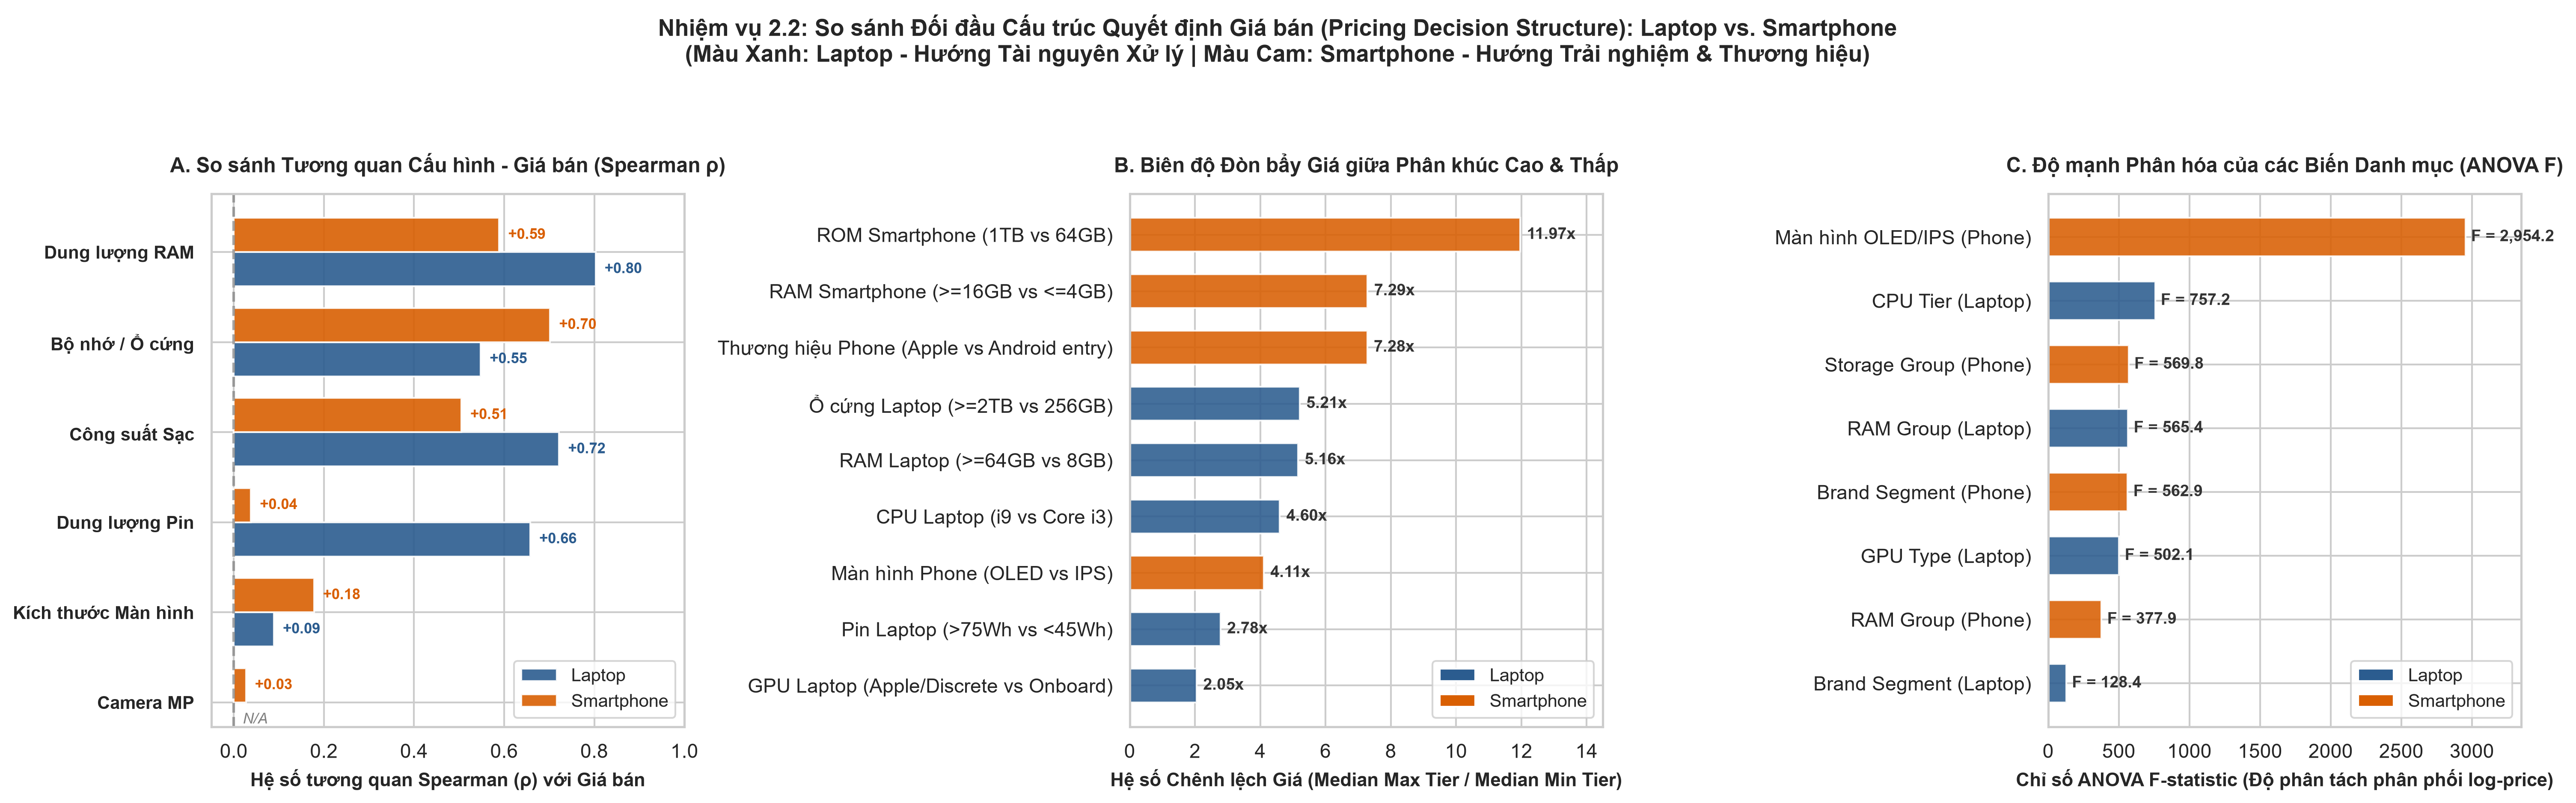

In [9]:
# Trực quan hóa đối đầu chuyên sâu cấu trúc quyết định giá (Fig 2.2)
plot_pricing_drivers_comparison(df, "src/eda/outputs/figures/fig_2_2_pricing_drivers_comparison.png")
from IPython.display import Image
Image("src/eda/outputs/figures/fig_2_2_pricing_drivers_comparison.png")
